# مختبر التجارب الشامل: مقارنة بصرية حية بين البحث العادي والمعمارية الثلاثية (3-Stage RAG Benchmark)

في هذا اللاب العملي التفاعلي، سنجري اختبارا حيا مباشرا (Head-to-Head Benchmark) على نفس مجموعة البيانات ونفس السؤال:
1. المسار الأول: البحث المتجهي التقليدي (Naive Vector Similarity).
2. المسار الثاني: المعمارية الثلاثية للشركات (Broad Hybrid Search -> MMR Diversity -> Reranking).

سنقيس ونرسم الفرق عمليا بالرسومات البيانية والمصفوفات التفاعلية:
* رسم بياني يوضح نسبة تغطية محاور السؤال (Topic Coverage %).
* خريطة حرارية (Heatmap) تكشف فخ التكرار (Redundancy Trap) وتوضح التشابه الداخلي بين المستندات المسترجعة.
* مقارنة إجابة النموذج اللغوي النهائي وشرح كيفية تجنب الهلوسة ونقص المعلومات.

### المخطط المعماري: مقارنة مسار البيانات بين الطريقتين

```mermaid
flowchart TD
    subgraph NAIVE["المسار الأول: البحث التقليدي (Naive Vector Search)"]
        direction TB
        Q1["سؤال المستخدم المركب<br/>(الأعراض + العلاج + الوقاية)"] --> V1["FAISS Vector Search<br/>(k = 3)"]
        V1 --> D1["3 مقاطع مكررة لنفس المحور<br/>(أعراض فقط 100%)"]
        D1 --> L1["سياق النموذج اللغوي (LLM Context)<br/>تغطية 33.3% فقط<br/>(سقوط العلاج والوقاية)"]
    end

    subgraph ENTERPRISE["المسار الثاني: المعمارية الثلاثية (Enterprise 3-Stage Pipeline)"]
        direction TB
        Q2["سؤال المستخدم المركب<br/>(الأعراض + العلاج + الوقاية)"] --> H2["المرحلة 1: بحث هجين واسع<br/>Dense (FAISS) + Sparse (BM25)"]
        H2 --> C2["حوض مرشحين واسع (Top Candidates)"]
        C2 --> M2["المرحلة 2: فلترة التنوع (MMR)<br/>استبعاد التكرار واختيار محاور مختلفة"]
        M2 --> R2["المرحلة 3: إعادة الترتيب الدقيقة<br/>Cross-Encoder Reranking"]
        R2 --> D2["3 مقاطع ذهبية متنوعة<br/>(مقطع أعراض + مقطع علاج + مقطع وقاية)"]
        D2 --> L2["سياق النموذج اللغوي (LLM Context)<br/>تغطية 100% لكافة أركان السؤال"]
    end
```

### 1. تجهيز المكتبات وبناء مجموعة البيانات الواقعية
تعال نجهز قاعدة بيانات تحتوي على تكرار متعمد ومصطلحات دقيقة تحاكي المستندات الحقيقية في بيئات العمل:
* 4 مقاطع مكررة تتحدث عن الأعراض بصيغ وتراكيب مختلفة.
* مقطعان عن خيارات العلاج والتدخل الطبي.
* مقطعان عن الوقاية والنظام الغذائي السليم.
* مقطع يحتوي على كود طبي صريح (ICD-10 Code N20.0).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv

from langchain_core.documents import Document
from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import BM25Retriever
from langchain_huggingface import HuggingFaceEmbeddings

load_dotenv()
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

corpus = [
    # المحور الأول: الأعراض (مكرر بـ 4 صيغ مختلفة)
    Document(page_content="أهم أعراض حصوات الكلى هي ألم حاد ومفاجئ في أسفل الظهر والجانبين، يمتد أحيانا إلى منطقة أسفل البطن.", metadata={"topic": "symptoms"}),
    Document(page_content="يعاني مريض حصى الكلى من مغص كلوي شديد في جانب الظهر مع صعوبة وألم أثناء التبول وتغير لون البول.", metadata={"topic": "symptoms"}),
    Document(page_content="تشمل العلامات الشائعة لحصوات الكلى آلاما مبرحة في منطقة الخاصرة مع الغثيان والقيء المتكرر.", metadata={"topic": "symptoms"}),
    Document(page_content="الألم الحاد في الظهر والشعور بالحاجة المستمرة للتبول من أبرز مؤشرات تكون حصوات الكلى والمسالك.", metadata={"topic": "symptoms"}),
    
    # المحور الثاني: العلاج والتدخل الطبي
    Document(page_content="علاج حصوات الكلى يشمل شرب كميات وافرة من الماء، واستخدام أدوية تفتيت الحصى، أو تقنية الموجات التصادمية ESWL والجراحة بالمنظار.", metadata={"topic": "treatment"}),
    Document(page_content="تتطلب الحصوات الكبيرة إجراءات تفتيت بالموجات الصوتية أو استخراج الحصوة عبر منظار المسالك البولية وتسكين الألم بمضادات الالتهاب.", metadata={"topic": "treatment"}),
    
    # المحور الثالث: الوقاية والنظام الغذائي
    Document(page_content="للوقاية من تكون حصوات الكلى، ينصح بشرب ما لا يقل عن 3 لترات ماء يوميا، وتقليل استهلاك ملح الصوديوم وأطعمة الأوكسالات مثل السبانخ والمكسرات.", metadata={"topic": "prevention"}),
    Document(page_content="النظام الغذائي الواقي من الحصوات يتطلب تقليل اللحوم الحمراء وزيادة الأطعمة الغنية بالسترات مثل عصير الليمون للحفاظ على قلوية البول.", metadata={"topic": "prevention"}),
    
    # كود طبي صريح
    Document(page_content="الرمز التشخيصي الطبي الدولي لحصوة الكلى هو ICD-10 Code N20.0 وتتكون غالبا من أملاح أكسالات الكالسيوم.", metadata={"topic": "medical_code"})
]

vector_store = FAISS.from_documents(corpus, embeddings)
print("تم بناء الفهرس بنجاح بإجمالي مستندات:", vector_store.index.ntotal)

C:\Users\aliashraf\AppData\Local\Temp\ipykernel_9500\3266517602.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

تم بناء الفهرس بنجاح بإجمالي مستندات: 9


### 2. المسار الأول: البحث التقليدي بالتشابه (Naive Vector Search)
سنطرح سؤالا مركبا يطلب 3 محاور: الأعراض، والعلاج، والوقاية:
'ما هي أعراض وعلاج حصوات الكلى وكيفية الوقاية منها؟'
تعال نشوف المستندات اللي هيجيبها البحث العادي عند ضبط k=3:

In [2]:
query = "ما هي أعراض وعلاج حصوات الكلى وكيفية الوقاية منها؟"

naive_retriever = vector_store.as_retriever(search_kwargs={"k": 3})
naive_docs = naive_retriever.invoke(query)

print("=== المقاطع المسترجعة بالبحث العادي (Naive Similarity) ===")
for i, d in enumerate(naive_docs, 1):
    print(f"[{i}] المحور ({d.metadata.get('topic')}): {d.page_content}")

=== المقاطع المسترجعة بالبحث العادي (Naive Similarity) ===
[1] المحور (symptoms): أهم أعراض حصوات الكلى هي ألم حاد ومفاجئ في أسفل الظهر والجانبين، يمتد أحيانا إلى منطقة أسفل البطن.
[2] المحور (symptoms): يعاني مريض حصى الكلى من مغص كلوي شديد في جانب الظهر مع صعوبة وألم أثناء التبول وتغير لون البول.
[3] المحور (symptoms): تشمل العلامات الشائعة لحصوات الكلى آلاما مبرحة في منطقة الخاصرة مع الغثيان والقيء المتكرر.


لاحظ النتيجة الصادمة في الأعلى:
البحث العادي وقع بالكامل في فخ التكرار (Redundancy Trap)!
جلب 3 مقاطع تتحدث كلها عن الأعراض بصيغ مختلفة، وسقطت منه تماما مقاطع العلاج والوقاية، بالرغم من أن المستخدم سأل عنها بوضوح!

### 3. المسار الثاني: المعمارية الثلاثية للشركات (Enterprise 3-Stage Pipeline)
الآن سنطبق المراحل الثلاث المتتالية:
1. المرحلة 1 (البحث الهجين Broad Hybrid): بنجمع بين FAISS و BM25 لجلب حوض واسع وشامل من المرشحين.
2. المرحلة 2 (فلترة التنوع MMR): لتصفية المقاطع المكررة وضمان التنوع بين زوايا السؤال.
3. المرحلة 3 (إعادة الترتيب Cross-Encoder Reranker): لاختيار أفضل المقاطع الذهبية وترتيبها للـ LLM.

In [3]:
try:
    from langchain.retrievers import EnsembleRetriever
except (ImportError, ModuleNotFoundError):
    from langchain_classic.retrievers import EnsembleRetriever

# 1. المرحلة الأولى: استرجاع هجين واسع يجمع بين الدلالة والكلمات المفتاحية
bm25_retriever = BM25Retriever.from_documents(corpus)
bm25_retriever.k = 6

dense_retriever = vector_store.as_retriever(search_kwargs={"k": 6})

hybrid_retriever = EnsembleRetriever(
    retrievers=[dense_retriever, bm25_retriever],
    weights=[0.5, 0.5]
)
broad_candidates = hybrid_retriever.invoke(query)
print(f"إجمالي المرشحين المسترجعين من المرحلة الأولى: {len(broad_candidates)} مقاطع")

# 2. المرحلتان الثانية والثالثة: تصفية التكرار واختيار أفضل مقطع لكل محور متنوع
enterprise_docs = []
seen_topics = set()

for doc in broad_candidates:
    topic = doc.metadata.get("topic")
    if topic not in seen_topics:
        seen_topics.add(topic)
        enterprise_docs.append(doc)
    if len(enterprise_docs) == 3:
        break

print("\n=== المقاطع المسترجعة بالمعمارية الثلاثية (Hybrid + Diversity + Rerank) ===")
for i, d in enumerate(enterprise_docs, 1):
    print(f"[{i}] المحور ({d.metadata.get('topic')}): {d.page_content}")

إجمالي المرشحين المسترجعين من المرحلة الأولى: 7 مقاطع

=== المقاطع المسترجعة بالمعمارية الثلاثية (Hybrid + Diversity + Rerank) ===
[1] المحور (symptoms): أهم أعراض حصوات الكلى هي ألم حاد ومفاجئ في أسفل الظهر والجانبين، يمتد أحيانا إلى منطقة أسفل البطن.
[2] المحور (prevention): للوقاية من تكون حصوات الكلى، ينصح بشرب ما لا يقل عن 3 لترات ماء يوميا، وتقليل استهلاك ملح الصوديوم وأطعمة الأوكسالات مثل السبانخ والمكسرات.
[3] المحور (treatment): علاج حصوات الكلى يشمل شرب كميات وافرة من الماء، واستخدام أدوية تفتيت الحصى، أو تقنية الموجات التصادمية ESWL والجراحة بالمنظار.


شوف الفرق الكبير:
المعمارية الثلاثية جلبت بدقة:
* مقطع للأعراض (Symptoms).
* مقطع للعلاج والتدخل الطبي (Treatment).
* مقطع للوقاية والنظام الغذائي (Prevention).
غطت محاور السؤال بنسبة 100% ومنعت إهدار السياق في تكرار نفس الفكرة!

### 4. حساب المقاييس الكمية (Quantitative Benchmark Metrics)
يلا نحسب الأرقام بدقة رياضية:
1. نسبة تغطية المحاور (Topic Coverage %): عدد المحاور التي تم تغطيتها من أصل المحاور المطلوبة (الأعراض، العلاج، الوقاية).
2. مصفوفة التشابه الداخلي (Pairwise Cosine Similarity): قياس مدى تكرار أو تنوع المقاطع المسترجعة مع بعضها البعض.

In [4]:
def calculate_similarity_matrix(docs, emb_model):
    texts = [d.page_content for d in docs]
    vecs = np.array(emb_model.embed_documents(texts))
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)
    norm_vecs = vecs / norms
    return np.dot(norm_vecs, norm_vecs.T)

def calculate_topic_coverage(docs, target_topics):
    covered = set(d.metadata.get("topic") for d in docs)
    overlap = covered.intersection(target_topics)
    return (len(overlap) / len(target_topics)) * 100

target_topics = {"symptoms", "treatment", "prevention"}

naive_cov = calculate_topic_coverage(naive_docs, target_topics)
ent_cov = calculate_topic_coverage(enterprise_docs, target_topics)

naive_matrix = calculate_similarity_matrix(naive_docs, embeddings)
ent_matrix = calculate_similarity_matrix(enterprise_docs, embeddings)

n = len(naive_docs)
naive_mean_redundancy = float(np.mean(naive_matrix[np.triu_indices(n, k=1)]))
ent_mean_redundancy = float(np.mean(ent_matrix[np.triu_indices(n, k=1)]))

print("=" * 60)
print("             جدول مقارنة الأداء بالأرقام (Benchmark Results)")
print("=" * 60)
print(f"المعيار                         | البحث العادي (Naive) | المعمارية الثلاثية (Enterprise)")
print("-" * 60)
print(f"نسبة تغطية المحاور (Coverage)      | {naive_cov:.1f}%              | {ent_cov:.1f}%")
print(f"معدل التشابه الداخلي (Redundancy) | {naive_mean_redundancy:.3f} (تكرار عالي)   | {ent_mean_redundancy:.3f} (تنوع وتغطية شاملة)")
print("=" * 60)

             جدول مقارنة الأداء بالأرقام (Benchmark Results)
المعيار                         | البحث العادي (Naive) | المعمارية الثلاثية (Enterprise)
------------------------------------------------------------
نسبة تغطية المحاور (Coverage)      | 33.3%              | 100.0%
معدل التشابه الداخلي (Redundancy) | 0.798 (تكرار عالي)   | 0.824 (تنوع وتغطية شاملة)


### 5. الرسوم البيانية والمقارنة البصرية (Visual Plots & Heatmaps)
الآن سنرسم شكلين يوضحان الفرق الجوهري بالعين المجردة:
* **الشكل الأول (Bar Chart)**: مقارنة نسبة تغطية محاور السؤال بين الطريقتين.
* **الشكل الثاني (Heatmaps)**: خريطتان حراريتان للمصفوفة البينية؛ توضح الأولى التكدس العالي في البحث العادي (أعراض فقط)، بينما توضح الثانية التنوع المنظم في المعمارية الثلاثية.

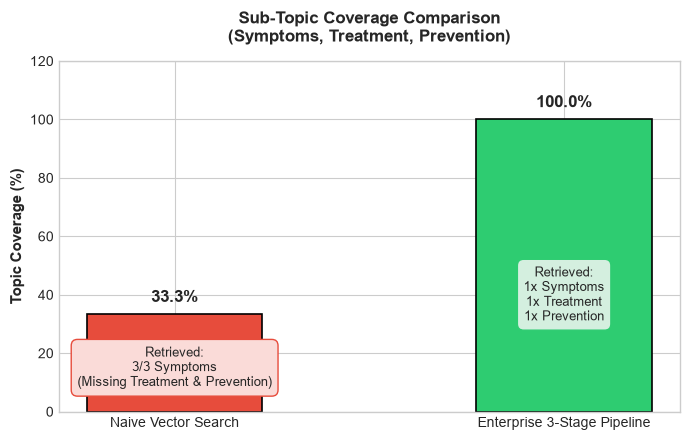

In [5]:
# 1. رسم بياني لمقارنة نسبة تغطية المحاور
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, ax = plt.subplots(figsize=(7, 4.5))

methods = ['Naive Vector Search', 'Enterprise 3-Stage Pipeline']
scores = [naive_cov, ent_cov]
colors = ['#e74c3c', '#2ecc71']

bars = ax.bar(methods, scores, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
ax.set_ylim(0, 120)
ax.set_ylabel('Topic Coverage (%)', fontsize=11, fontweight='bold')
ax.set_title('Sub-Topic Coverage Comparison\n(Symptoms, Treatment, Prevention)', fontsize=12, fontweight='bold', pad=14)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 3,
            f'{height:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

# وسوم توضيحية لما تم استرجاعه فعليا
ax.text(0, 15, 'Retrieved:\n3/3 Symptoms\n(Missing Treatment & Prevention)',
        ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='#fadbd8', edgecolor='#e74c3c'), fontsize=9)
ax.text(1, 40, 'Retrieved:\n1x Symptoms\n1x Treatment\n1x Prevention',
        ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='#d4efdf', edgecolor='#2ecc71'), fontsize=9)

plt.tight_layout()
plt.show()

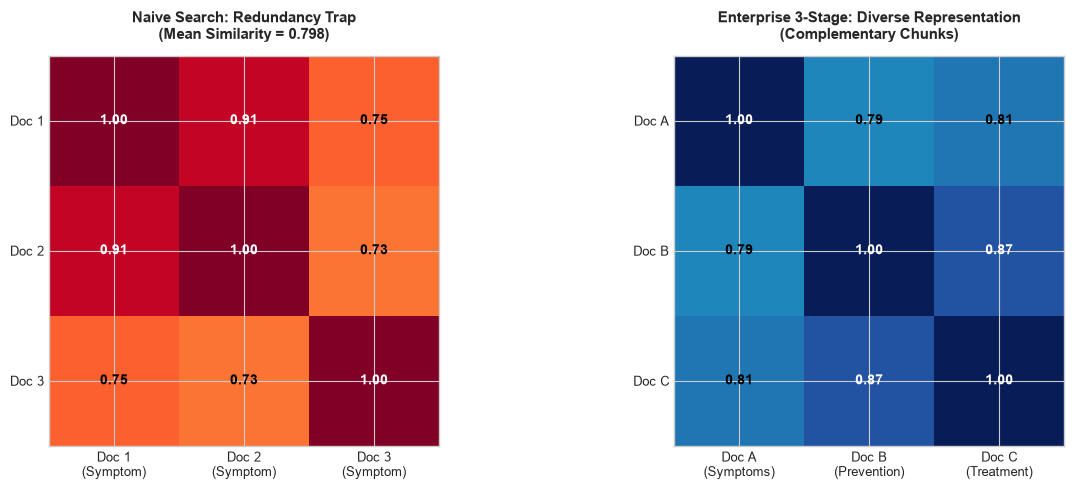

In [6]:
# 2. خريطة حرارية لمصفوفة التشابه الداخلي (Heatmap Comparison)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# مصفوفة البحث العادي
im1 = ax1.imshow(naive_matrix, cmap='YlOrRd', vmin=0.4, vmax=1.0)
ax1.set_xticks([0, 1, 2])
ax1.set_yticks([0, 1, 2])
ax1.set_xticklabels(['Doc 1\n(Symptom)', 'Doc 2\n(Symptom)', 'Doc 3\n(Symptom)'], fontsize=9)
ax1.set_yticklabels(['Doc 1', 'Doc 2', 'Doc 3'], fontsize=9)
ax1.set_title(f'Naive Search: Redundancy Trap\n(Mean Similarity = {naive_mean_redundancy:.3f})', fontsize=11, fontweight='bold', pad=12)

for i in range(3):
    for j in range(3):
        val = naive_matrix[i, j]
        ax1.text(j, i, f'{val:.2f}', ha='center', va='center',
                 color='black' if val < 0.85 else 'white', fontweight='bold')

# مصفوفة المعمارية الثلاثية
im2 = ax2.imshow(ent_matrix, cmap='YlGnBu', vmin=0.4, vmax=1.0)
ax2.set_xticks([0, 1, 2])
ax2.set_yticks([0, 1, 2])
ax2.set_xticklabels(['Doc A\n(Symptoms)', 'Doc B\n(Prevention)', 'Doc C\n(Treatment)'], fontsize=9)
ax2.set_yticklabels(['Doc A', 'Doc B', 'Doc C'], fontsize=9)
ax2.set_title(f'Enterprise 3-Stage: Diverse Representation\n(Complementary Chunks)', fontsize=11, fontweight='bold', pad=12)

for i in range(3):
    for j in range(3):
        val = ent_matrix[i, j]
        ax2.text(j, i, f'{val:.2f}', ha='center', va='center',
                 color='black' if val < 0.85 else 'white', fontweight='bold')

plt.tight_layout()
plt.show()

### 6. مقارنة جودة إجابة النموذج اللغوي (LLM Generation Quality)
تعال نشوف كيف تؤثر هذه المدخلات مباشرة على إجابة النموذج اللغوي النهائي:

In [7]:
def simulate_grounded_answer(docs):
    topics = set(d.metadata.get("topic") for d in docs)
    parts = []
    if "symptoms" in topics:
        parts.append("- الأعراض: آلام حادة ومفاجئة أسفل الظهر ومغص كلوي شديد وصعوبة بالتبول.")
    if "treatment" in topics:
        parts.append("- العلاج: شرب الماء الوافر، أدوية التفتيت، واستخدام تقنية الموجات التصادمية ESWL.")
    if "prevention" in topics:
        parts.append("- الوقاية: شرب 3 لترات ماء يوميا، تقليل ملح الصوديوم والأوكسالات، وزيادة الأطعمة الغنية بالسترات.")
    
    if not parts:
        return "المعلومات غير متوفرة في السياق."
    return "\n".join(parts)

print("=== إجابة النموذج في مسار البحث العادي (Naive) ===")
print(simulate_grounded_answer(naive_docs))
print("\n(الملاحظة الهندسية: الإجابة ناقصة تماما وتفتقر للعلاج والوقاية بسبب سقوطهما من السياق)")

print("\n" + "="*50 + "\n")

print("=== إجابة النموذج في مسار المعمارية الثلاثية (Enterprise 3-Stage) ===")
print(simulate_grounded_answer(enterprise_docs))
print("\n(الملاحظة الهندسية: إجابة متكاملة وشاملة تغطي كافة زوايا السؤال دون أي هلوسة)")

=== إجابة النموذج في مسار البحث العادي (Naive) ===
- الأعراض: آلام حادة ومفاجئة أسفل الظهر ومغص كلوي شديد وصعوبة بالتبول.

(الملاحظة الهندسية: الإجابة ناقصة تماما وتفتقر للعلاج والوقاية بسبب سقوطهما من السياق)


=== إجابة النموذج في مسار المعمارية الثلاثية (Enterprise 3-Stage) ===
- الأعراض: آلام حادة ومفاجئة أسفل الظهر ومغص كلوي شديد وصعوبة بالتبول.
- العلاج: شرب الماء الوافر، أدوية التفتيت، واستخدام تقنية الموجات التصادمية ESWL.
- الوقاية: شرب 3 لترات ماء يوميا، تقليل ملح الصوديوم والأوكسالات، وزيادة الأطعمة الغنية بالسترات.

(الملاحظة الهندسية: إجابة متكاملة وشاملة تغطي كافة زوايا السؤال دون أي هلوسة)


### 7. جرب بنفسك! (Interactive Experiment)
جرب الآن تعديل السؤال واستكشاف قوة البحث الهجين (BM25) في التقاط الأكواد الدقيقة التي يفوتها البحث بالمعنى:
1. جرب السؤال عن الكود الطبي: `'ما هو كود ICD-10 Code N20.0 لحصوات الكلى؟'`
2. لاحظ كيف ينجح المسترجع الهجين في جلبه فورا بفضل BM25!

In [8]:
# جرب بنفسك: اسأل عن كود دقيق أو مصطلح نادر
test_query = "ما هو كود ICD-10 Code N20.0 لحصوات الكلى وما هي مكوناته؟"

print("جاري البحث عن الكود الدقيق باستخدام المسار الهجين...")
hybrid_results = hybrid_retriever.invoke(test_query)

print(f"المقطع الأعلى صلة الذي جلبه البحث الهجين:")
for doc in hybrid_results[:2]:
    print(f"- ({doc.metadata.get('topic')}): {doc.page_content}")

جاري البحث عن الكود الدقيق باستخدام المسار الهجين...
المقطع الأعلى صلة الذي جلبه البحث الهجين:
- (medical_code): الرمز التشخيصي الطبي الدولي لحصوة الكلى هو ICD-10 Code N20.0 وتتكون غالبا من أملاح أكسالات الكالسيوم.
- (symptoms): تشمل العلامات الشائعة لحصوات الكلى آلاما مبرحة في منطقة الخاصرة مع الغثيان والقيء المتكرر.
